# 2. Part A: the three rounds with institution information (2025, 2026 R1, 2026 R2)

**Question:** why is the chance of failing so high, and how does the graduating institute (public, private, abroad, and the individual institute) relate to it?

**Structure of the analysis:**
1. Public / private / abroad, in each round
2. Each institute: first-attempt pass rate, compared with what is **expected**, with false-discovery-rate correction
3. Provinces
4. Regression models (controlling for field, round and previous failures)
5. What happens after failing, by institute type

**Statistical principles:**
- Within one round each person appears once, so **Wilson** confidence intervals are used. When rounds are pooled a person appears several times, so a **person-cluster bootstrap** and **cluster-robust** standard errors are used.
- Institutes are compared **only on first attempts** (one row per person), because retaking candidates are a selected group.
- Each institute is compared with the expectation for its own type, round and field (indirect standardisation), so that differences in round difficulty are not blamed on institutes.

In [14]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath('../src'))          # the notebooks live in notebooks/, the code in src/
import numpy as np
import pandas as pd
from exitexam import config as C, cleaning as cl, linking as lk, stats_utils as su, plotting as P, pipeline
from exitexam import analysis_a as A, analysis_b as B

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
P.setup()

In [15]:
clean, excluded, audit, h = pipeline.load_all()
a = A.prepare(h)          # Part A rows only (rounds with institution info); history comes from the 5-round linkage
A.coverage(h, a)

type,exam,Abroad,Private,Public,total_valid,rows_without_institution,institutes_seen
0,2025,92,8097,1148,9337,0,46
1,2026-R1,50,6137,746,6933,0,46
2,2026-R2,85,4990,973,6048,2,39


## 2.1 Public, private and abroad

First the pass rate in each round, then the first-attempt and retaking pass rates separately.

In [16]:
ts, type_pooled = A.type_summary(a)
display(ts)
type_pooled

,exam,type,rows,passes,pass_rate,ci_low,ci_high,mean_score,median_score,sd_score,near_miss_share_of_fails,n_first_attempt,pass_rate_first,n_retaking,pass_rate_retaking
0,2025,Public,1148,915,0.797,0.773,0.819,250.799,258.750,43.816,0.197,1007,0.853,141,0.397
1,2025,Private,8097,2719,0.336,0.326,0.346,195.810,195.750,43.065,0.111,5997,0.360,2100,0.266
2,2025,Abroad,92,68,0.739,0.641,0.818,239.601,252.000,36.090,0.292,77,0.792,15,0.467
3,2026-R1,Public,746,371,0.497,0.462,0.533,210.776,213.750,53.452,0.133,547,0.649,199,0.080
4,2026-R1,Private,6137,389,0.063,0.058,0.070,151.842,148.500,37.547,0.021,1830,0.125,4307,0.037
5,2026-R1,Abroad,50,13,0.260,0.159,0.396,183.240,183.375,40.167,0.135,32,0.344,18,0.111
6,2026-R2,Public,973,761,0.782,0.755,0.807,249.017,258.750,51.660,0.113,670,0.909,303,0.502
7,2026-R2,Private,4990,1075,0.215,0.204,0.227,175.728,171.000,47.647,0.064,1613,0.309,3377,0.171
8,2026-R2,Abroad,85,53,0.624,0.517,0.719,223.147,231.750,48.883,0.125,58,0.776,27,0.296


,type,rows,persons,passes,rate,ci_low,ci_high
0,Abroad,227,185,134,0.590,0.520,0.668
1,Private,19224,12152,4183,0.218,0.212,0.224
2,Public,2867,2437,2047,0.714,0.694,0.734


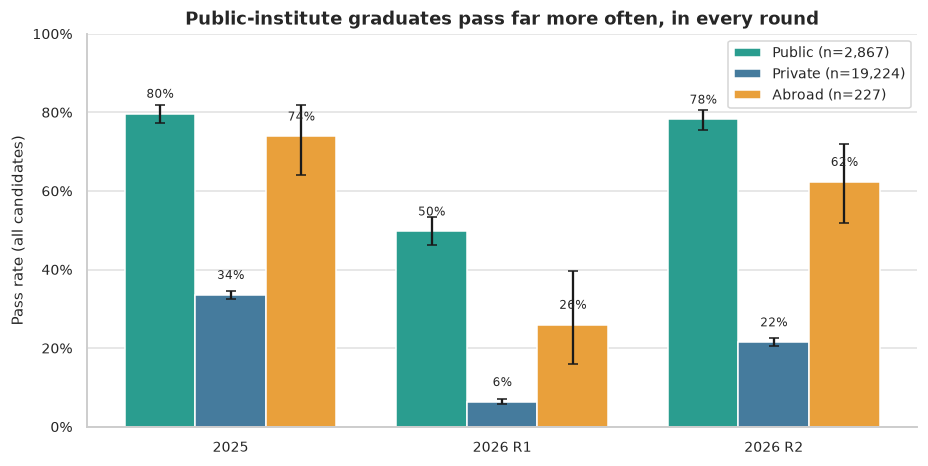

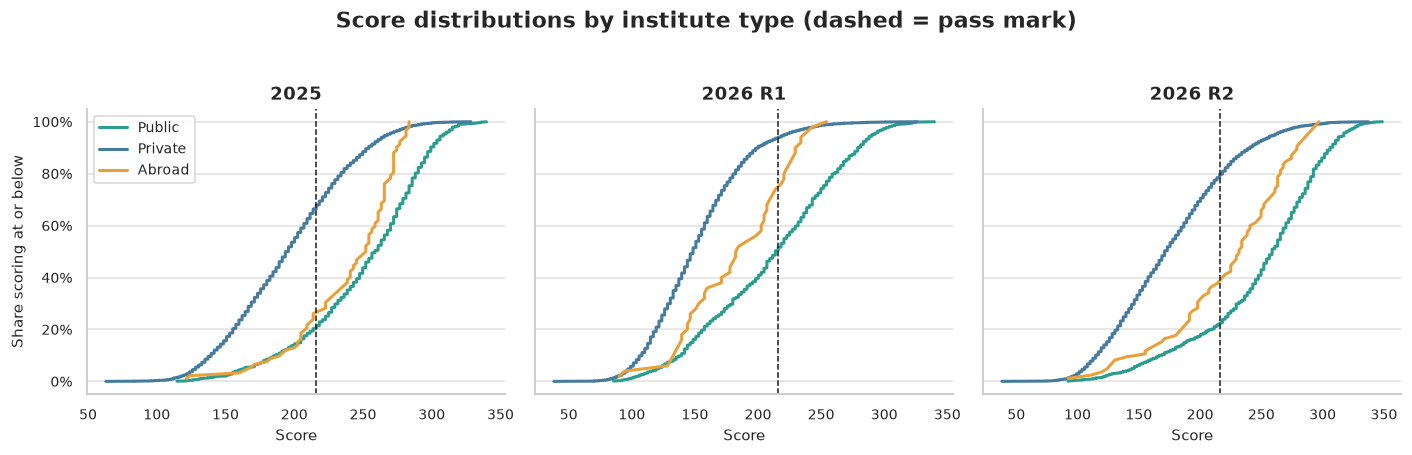

In [17]:
P.save(A.fig_type_by_round(ts), 'A01_pass_rate_by_type')
P.save(A.fig_type_ecdf(a), 'A02_scores_by_type')

**Statistical tests:** difference between public and private, **odds ratio**, **Cramér's V** and **Cliff's delta** (effect sizes). In large samples the p-value is almost always tiny, so the effect size matters more.

In [18]:
display(A.type_tests(a))
A.odds_by_round(a)

,scope,public_pass,private_pass,diff_private_minus_public,diff_ci_low,diff_ci_high,odds_ratio_public_vs_private,or_low,or_high,chi2_p_3types,cramers_v,cliffs_delta_public_vs_private,note
0,2025,0.797,0.336,-0.461,-0.487,-0.436,7.767,6.679,9.034,0.000,0.317,0.626,
1,2026-R1,0.497,0.063,-0.434,-0.470,-0.398,14.619,12.254,17.440,0.000,0.429,0.613,
2,2026-R2,0.782,0.215,-0.567,-0.595,-0.538,13.073,11.068,15.441,0.000,0.456,0.691,
3,pooled,0.714,0.218,-0.496,-0.514,-0.479,8.976,8.220,9.801,0.000,0.374,0.625,pooled rows repeat persons: treat p-values as ...


,round,scope,public_pass,private_pass,or_public_vs_private,or_low,or_high
0,2025,all candidates,0.797,0.336,7.767,6.679,9.034
1,2025,first attempts,0.853,0.360,10.303,8.586,12.362
2,2026-R1,all candidates,0.497,0.063,14.619,12.254,17.440
3,2026-R1,first attempts,0.649,0.125,12.927,10.336,16.166
4,2026-R2,all candidates,0.782,0.215,13.073,11.068,15.441
5,2026-R2,first attempts,0.909,0.309,22.288,16.784,29.597


,scope,type,share_of_candidates,share_of_failures
0,2025,Public,0.123,0.041
1,2025,Private,0.867,0.954
2,2025,Abroad,0.010,0.004
3,2026-R1,Public,0.108,0.061
4,2026-R1,Private,0.885,0.933
5,2026-R1,Abroad,0.007,0.006
6,2026-R2,Public,0.161,0.051
7,2026-R2,Private,0.825,0.941
8,2026-R2,Abroad,0.014,0.008
9,pooled,Public,0.128,0.051


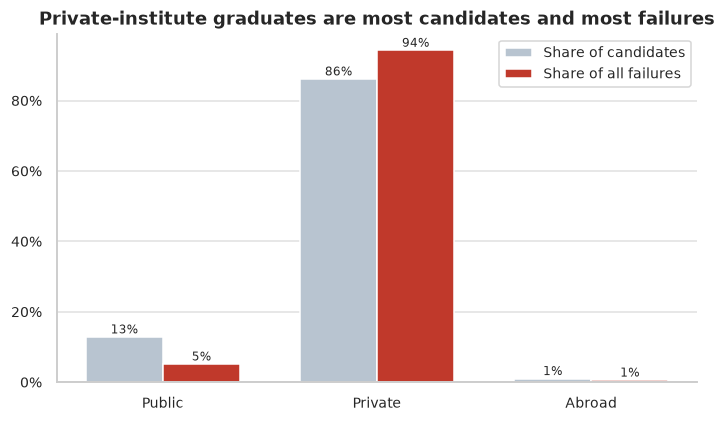

In [19]:
bd = A.burden(a)
display(bd)
P.save(A.fig_burden(bd), 'A09_share_of_failures')

## 2.2 Institutes

**How to read:** `obs_over_expected` = (observed passes) / (passes predicted from the institute type, round and field). A value near 1 means as expected, well above 1 better, well below 1 worse. `p_bh` is the p-value adjusted by **Benjamini-Hochberg** (false discovery rate), which reduces false alarms when many institutes are compared together. `pass_rate_first_shrunk` is the **empirical-Bayes** shrinkage: very high or very low rates of small institutes are pulled toward the average.

In [20]:
meta, hetero, variance, base_model, first = A.institute_tables(a)
cols = ['label', 'type', 'n_first', 'pass_rate_first', 'ci_low', 'ci_high', 'pass_rate_first_shrunk',
        'obs_over_expected', 'z', 'p_bh', 'flag', 'pass_rate_all_attempts', 'ranked']
meta[cols]

,label,type,n_first,pass_rate_first,ci_low,ci_high,pass_rate_first_shrunk,obs_over_expected,z,p_bh,flag,pass_rate_all_attempts,ranked
0,Herat - Ghalib,Private,144,0.660,0.579,0.732,0.615,2.036,8.698,0.000,better than expected,0.524,True
1,Kabul - Cheragh,Private,65,0.523,0.404,0.640,0.470,1.706,3.855,0.000,better than expected,0.467,True
2,Kabul - Katib,Private,158,0.519,0.442,0.596,0.494,1.639,5.549,0.000,better than expected,0.364,True
3,Kandahar - Malalai,Private,200,0.510,0.441,0.578,0.491,1.580,5.727,0.000,better than expected,0.394,True
4,Kabul - Ghalib,Private,203,0.473,0.405,0.541,0.457,1.495,4.867,0.000,better than expected,0.360,True
5,Herat - Hariwa,Private,143,0.434,0.355,0.515,0.417,1.623,4.657,0.000,better than expected,0.383,True
6,Herat - Jami,Private,256,0.418,0.359,0.479,0.410,1.294,3.287,0.003,better than expected,0.368,True
7,Kabul - Spin Ghar,Private,411,0.414,0.367,0.462,0.408,1.288,4.070,0.000,better than expected,0.298,True
8,Balkh - Aria,Private,240,0.396,0.336,0.459,0.389,1.209,2.279,0.039,better than expected,0.247,True
9,Helmand - Bost,Private,276,0.384,0.329,0.443,0.379,1.261,2.927,0.007,better than expected,0.285,True


In [21]:
display(hetero)       # do institutes differ more than chance allows?
variance              # how much of the score variance each grouping explains

,type,institutes,chi2,dof,p_value,sd_of_true_rates_between_institutes,mean_rate
0,Private,33,455.308,32,0.000,0.098,0.307
1,Public,8,42.461,7,0.000,0.048,0.823


,grouping,groups,eta_squared,omega_squared_adjusted
0,Institute type,2,0.218,0.218
1,Province,14,0.095,0.094
2,Institute,46,0.275,0.272
3,Round,3,0.061,0.061
4,Field,2,0.005,0.005


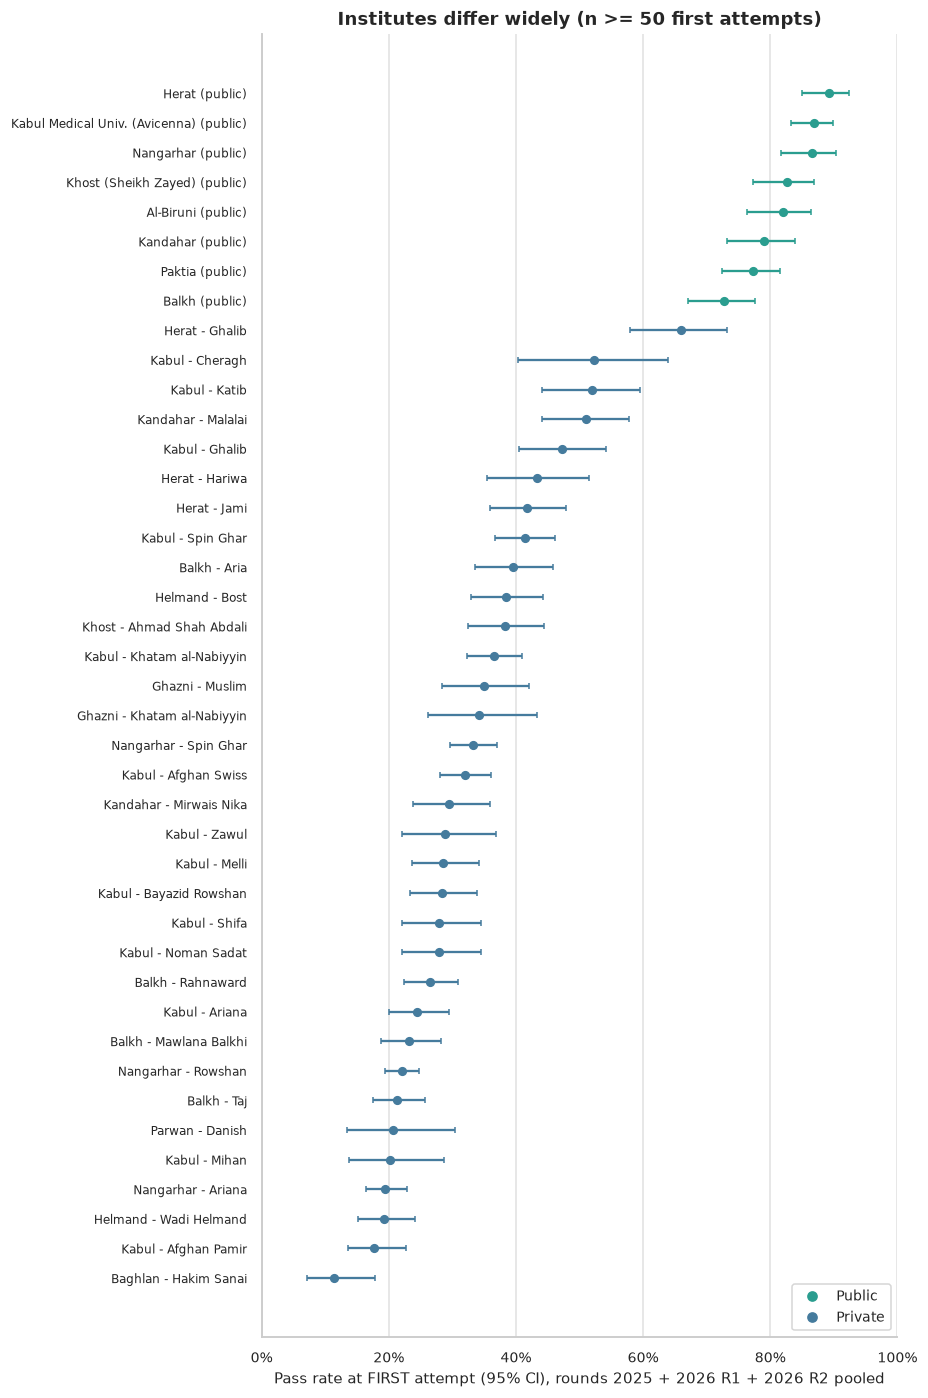

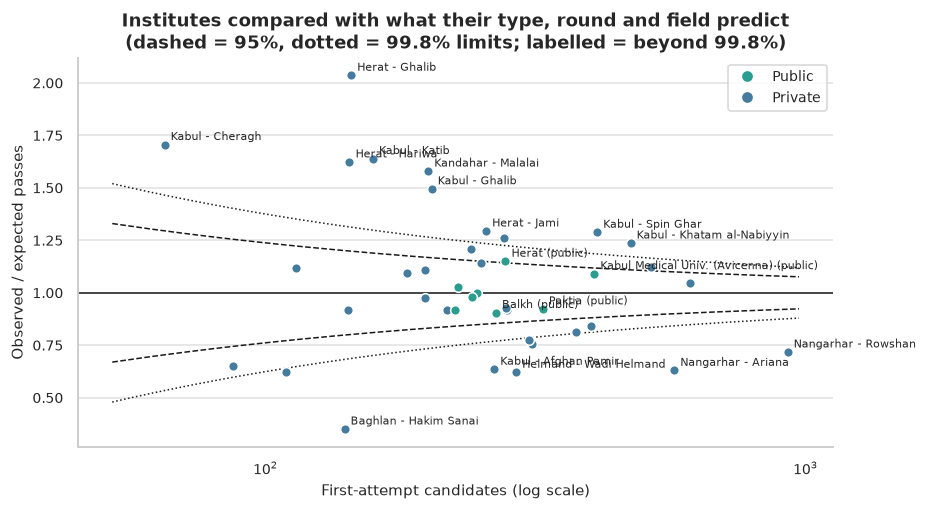

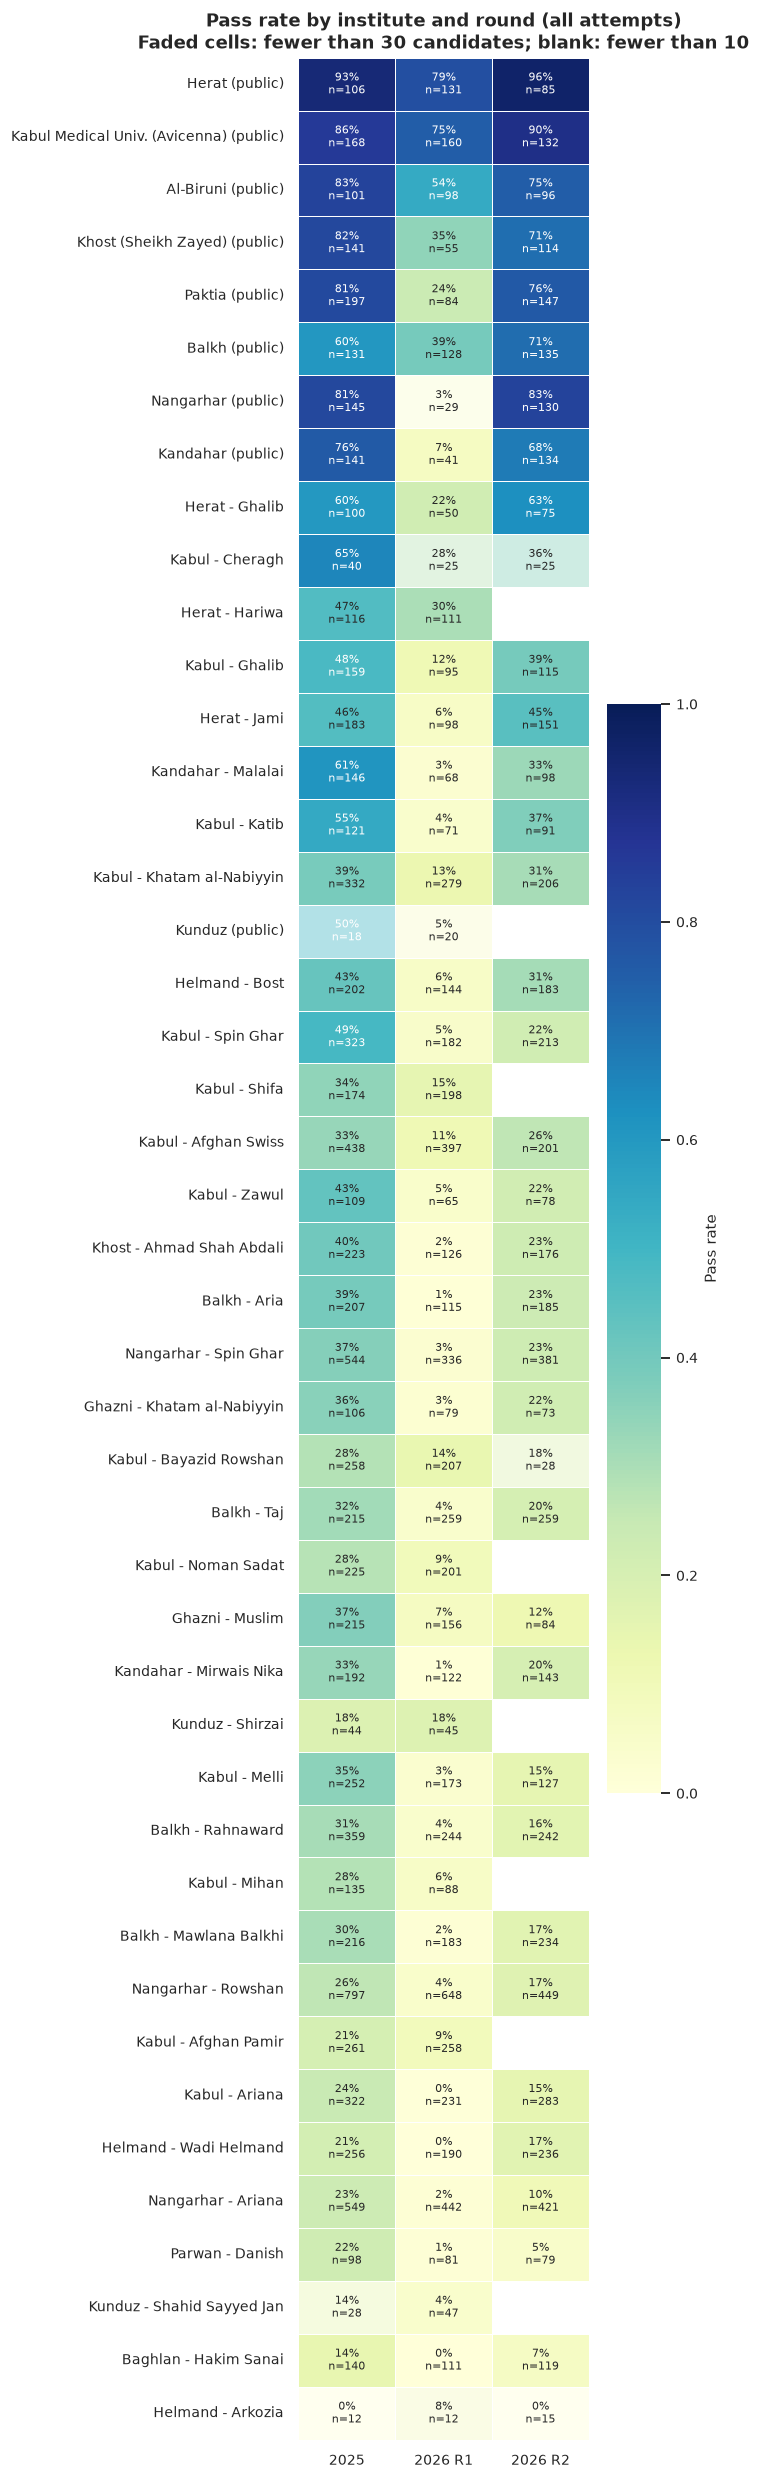

In [22]:
P.save(A.fig_institutes(meta), 'A03_institutes_first_attempt')
P.save(A.fig_funnel(meta, first), 'A04_institutes_funnel')
rate_m, n_m = A.institute_round_matrix(a)
P.save(A.fig_heatmap(rate_m, n_m), 'A05_institute_by_round')

## 2.3 Provinces

Province differences are mixed with institute differences (several institutes per province), so they are descriptive only and are not a "province effect".

,type,province_en,n_first,passes,mean_score,pass_rate_first,ci_low,ci_high
0,Private,Herat,543,264,211.749,0.486,0.444,0.528
1,Private,Kandahar,417,166,198.399,0.398,0.352,0.446
2,Private,Khost,251,96,196.996,0.382,0.325,0.444
3,Private,Ghazni,297,103,193.402,0.347,0.295,0.403
4,Private,Kabul,3608,1175,191.501,0.326,0.311,0.341
5,Private,Helmand,575,163,182.598,0.283,0.248,0.322
6,Private,Balkh,1323,352,180.145,0.266,0.243,0.291
7,Private,Nangarhar,2108,518,181.171,0.246,0.228,0.265
8,Private,Parwan,87,18,170.069,0.207,0.135,0.304
9,Private,Kunduz,71,11,162.729,0.155,0.089,0.257


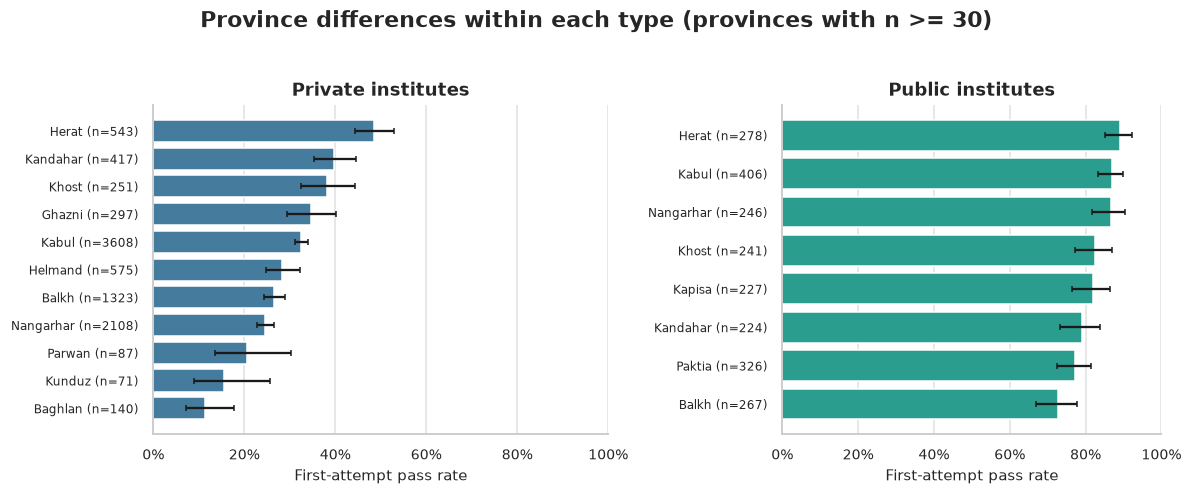

In [23]:
prov = A.province_table(a)
display(prov)
P.save(A.fig_province(prov), 'A06_province')

## 2.4 Regression models

Logistic regression of **passing**, with **cluster-robust** standard errors at the person level.
- **MA1:** type + field + round
- **MA2:** + number of previous failures
- **MA3:** first attempts only

If the private/public odds ratio stays large in MA3 (first attempts only), the difference is not just due to repeat candidates.

In [24]:
models, d, X2 = A.models(a)
mt = B.models_to_table(models)
mt[['model', 'term', 'odds_ratio', 'or_low', 'or_high', 'p_value', 'n_rows', 'n_persons', 'mcfadden_r2']]

,model,term,odds_ratio,or_low,or_high,p_value,n_rows,n_persons,mcfadden_r2
0,MA1 type + field + round,const,5.250,4.648,5.931,0.000,22316,14769,0.178
1,MA1 type + field + round,type[Abroad],0.494,0.351,0.695,0.000,22316,14769,0.178
2,MA1 type + field + round,type[Private],0.087,0.077,0.097,0.000,22316,14769,0.178
3,MA1 type + field + round,field_c[Stomatology],1.308,1.197,1.430,0.000,22316,14769,0.178
4,MA1 type + field + round,round[2026-R1],0.148,0.135,0.161,0.000,22316,14769,0.178
5,MA1 type + field + round,round[2026-R2],0.616,0.571,0.666,0.000,22316,14769,0.178
6,MA2 + previous failures,const,5.289,4.743,5.899,0.000,22316,14769,0.203
7,MA2 + previous failures,type[Abroad],0.506,0.371,0.689,0.000,22316,14769,0.203
8,MA2 + previous failures,type[Private],0.107,0.096,0.119,0.000,22316,14769,0.203
9,MA2 + previous failures,field_c[Stomatology],1.356,1.240,1.483,0.000,22316,14769,0.203


,type,history,round,predicted_pass,ci_low,ci_high
0,Public,First attempt,2025,0.841,0.826,0.855
1,Public,First attempt,2026-R1,0.511,0.482,0.539
2,Public,First attempt,2026-R2,0.828,0.812,0.842
3,Public,Failed once before,2025,0.694,0.662,0.725
4,Public,Failed once before,2026-R1,0.309,0.282,0.337
5,Public,Failed once before,2026-R2,0.673,0.642,0.703
6,Private,First attempt,2025,0.361,0.348,0.373
7,Private,First attempt,2026-R1,0.100,0.092,0.109
8,Private,First attempt,2026-R2,0.339,0.322,0.357
9,Private,Failed once before,2025,0.195,0.180,0.211


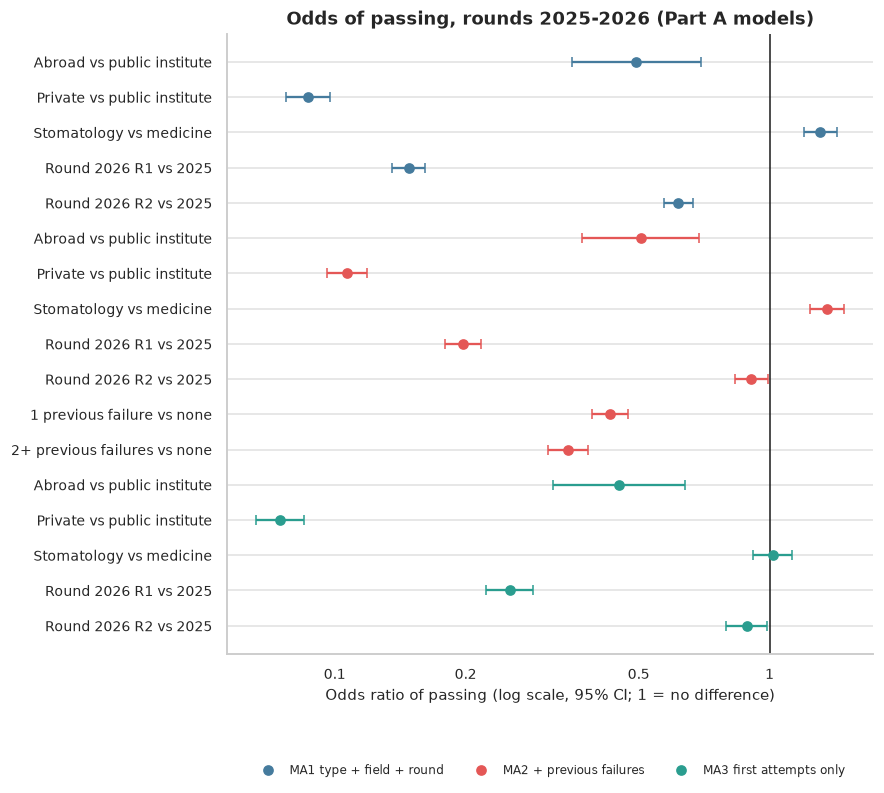

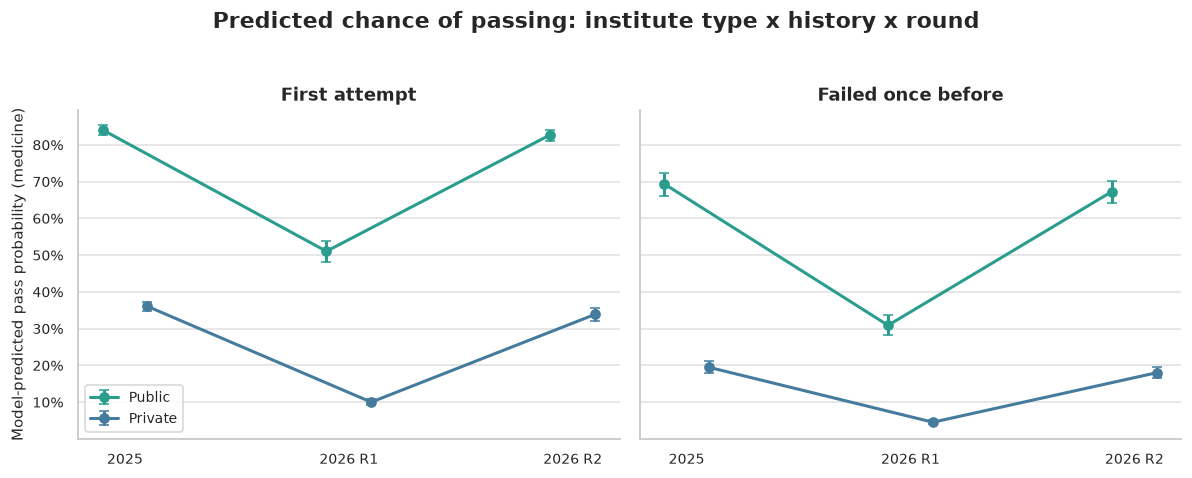

In [25]:
grid = A.predicted_grid(models['MA2 + previous failures'], X2, d)
display(grid)
P.save(B.fig_forest(models, 'Odds of passing, rounds 2025-2026 (Part A models)', terms=['type', 'field_c', 'prior', 'round']), 'A07_model_odds_ratios')
P.save(A.fig_predicted(grid), 'A08_predicted_probabilities')

## 2.5 After failing (by institute type)

Only two transitions exist here: 2025 > 2026 R1 and 2026 R1 > 2026 R2. The full five-round transitions are in Part B.

,transition,type,failed,returned,return_rate,ret_low,ret_high,pass_given_return,pass_low,pass_high
0,2025 > 2026-R1,Public,233,148,0.635,0.572,0.694,0.054,0.028,0.103
1,2025 > 2026-R1,Private,5378,3844,0.715,0.703,0.727,0.035,0.030,0.042
2,2025 > 2026-R1,Abroad,24,16,0.667,0.467,0.820,0.125,0.035,0.360
3,2026-R1 > 2026-R2,Public,375,255,0.680,0.631,0.725,0.573,0.511,0.632
4,2026-R1 > 2026-R2,Private,5748,2894,0.503,0.491,0.516,0.190,0.176,0.204
5,2026-R1 > 2026-R2,Abroad,37,24,0.649,0.488,0.782,0.333,0.180,0.533


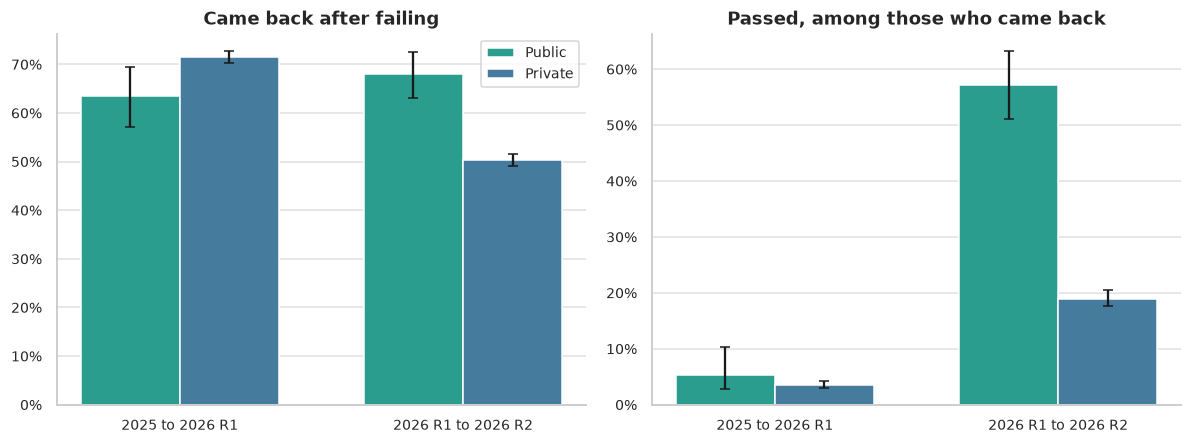

In [26]:
tt = A.type_transitions(h, a)
display(tt)
P.save(A.fig_type_transitions(tt), 'A10_after_failure_by_type')

## 2.6 Limitations (to state in the paper)

- Part A is **observational**: private institutes may differ in entrance (concours) scores, socio-economic background and more. We show **associations**, not causes.
- 2026 R2 contains medicine only (no stomatology).
- The number of public institutes is small (9), and some (for example Kunduz) have very few candidates.
- Institute type and name are extracted from text in the files; two rows have no usable institution.